## 1. Evaluation setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)

In [2]:
## seeding for consistency across restarts and reruns
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
#torch.set_num_threads(4) # Not entirely necessary, depending on the # of cores your machine has. Definitely should not crash your laptop, but I use it for the notebook to run quicker. 

### Checkpoint 1 background

1. CSV reading
2. Cleanings
3. Applied Splitting Logic

In [3]:
df = pd.read_csv("T_ONTIME_REPORTING.csv")
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"])
clean = df[(df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)].copy()   # drop flights with no outcome
clean = clean.drop_duplicates()
clean["DEP_HOUR"] = (clean["CRS_DEP_TIME"] // 100) % 24
print("Clean flights:", len(clean), " Missing values:", int(clean.isna().sum().sum()))

Clean flights: 522269  Missing values: 0


In [4]:
#Splitting 
train_full = clean[clean["FL_DATE"] < "2025-01-22"].reset_index(drop=True)
test = clean[clean["FL_DATE"] >= "2025-01-22"].reset_index(drop=True)
fit = train_full[train_full["FL_DATE"] < "2025-01-15"].reset_index(drop=True)
val = train_full[train_full["FL_DATE"] >= "2025-01-15"].reset_index(drop=True)

# leakage / split checks, section 3
assert train_full["FL_DATE"].max() < test["FL_DATE"].min()
assert fit["FL_DATE"].max() < val["FL_DATE"].min()
FORBIDDEN = {"ARR_DEL15", "CANCELLED", "DIVERTED", "FL_DATE"}

split = pd.DataFrame({
    "Rows": [len(fit), len(val), len(train_full), len(test)],
    "Dates": ["Jan 1-14", "Jan 15-21", "Jan 1-21", "Jan 22-31"],
    "Delay rate": [d["ARR_DEL15"].mean() for d in (fit, val, train_full, test)],
}, index=["Fit (tuning)", "Validation (tuning)", "Train (final)", "Test"]).round(3)
display(split)

,Rows,Dates,Delay rate
Fit (tuning),237115,Jan 1-14,0.233
Validation (tuning),116049,Jan 15-21,0.172
Train (final),353164,Jan 1-21,0.213
Test,169105,Jan 22-31,0.135


## 2. Baselines

1. Benchmark: "model" that always predicts on time, should have a recall of 0%
2. Simple baseline: PyTorch logistic regression on DEP_HOUR, DAY_OF_WEEK and DISTANCE (the patterns from the Checkpoint 1 EDA)
3. Full model: the same PyTorch logistic regression on all predictors

In [5]:
# Benchmark model: every flight gets a late probability of 0, so it always predicts "on time"
p_bench = np.zeros(len(test))
print("Accuracy:", round(1 - test["ARR_DEL15"].mean(), 3), " Recall:", 0.0)

Accuracy: 0.865  Recall: 0.0


## 3. Preprocessing (fit on training data only)

- Numerics DISTANCE, CRS_ELAPSED_TIME are standardized -> changing of the units, not affecting what the model is learning
- Categorical DEP_HOUR, DAY_OF_WEEK, OP_UNIQUE_CARRIER, ORIGIN, DES): one-hot encoded
  - DEP_HOUR is categorical because the delay pattern in Figure 2 is not linear
  - Categories with fewer than 100 training flights are grouped as infrequent, and unseen categories are handled the same way
- MONTH is dropped ("January"), synonymous across all datapoints in test, validation, and train. Adds no importance with the current training setup, but would be more important if one were to train on all 12 months.

In [6]:
# Columns for full model
FULL_CAT = ["DEP_HOUR", "DAY_OF_WEEK", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST"]
FULL_NUM = ["CRS_ELAPSED_TIME", "DISTANCE"]

# Columns for simple baseline
SIMPLE_CAT = ["DEP_HOUR", "DAY_OF_WEEK"]
SIMPLE_NUM = ["DISTANCE"]

assert not FORBIDDEN & set(FULL_CAT + FULL_NUM)   # no leakage columns as predictors

def make_pre(cat, num):
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), cat),
    ], sparse_threshold=0)                      # dense output

def to_tensor(pre, d):
    return torch.tensor(pre.transform(d), dtype=torch.float32)

## 4. Model: logistic regression in PyTorch

- Model: logistic_regression class (nn.Module), one linear layer that outputs a logit
- Loss: BCEWithLogitsLoss, a sigmoid followed by binary cross-entropy, with pos_weight so late flights count more (on-time count / late count)
- Optimizer: Adam
- Data: a Data class (Dataset) and a DataLoader with batches of 4,096 rows
- The sigmoid is applied in predict() to turn logits into probabilities

In [7]:
# Data class
class Data(Dataset):
    def __init__(self, x, y):
        self.x, self.y, self.len = x, y.view(-1, 1), len(x)

    def __getitem__(self, index):
        return self.x[index], self.y[index]

    def __len__(self):
        return self.len

class logistic_regression(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.linear = nn.Linear(n_inputs, 1)

    def forward(self, x):
        return self.linear(x)

def labels(d):
    return torch.tensor(d["ARR_DEL15"].values, dtype=torch.float32)

def predict(model, x):
    with torch.no_grad():
        return torch.sigmoid(model(x)).squeeze(1).numpy()

### Define Hyperparam settings

In [8]:
yf, yv = labels(fit), labels(val)

criterion = nn.BCEWithLogitsLoss(pos_weight=(1 - yf.mean()) / yf.mean())   # late flights count more
batch_size = 4096
epochs = 5
learning_rate = 0.01
weight_decay = 0.0001

def train_model(x, y, seed=SEED):
    torch.manual_seed(seed)
    trainloader = DataLoader(Data(x, y), batch_size=batch_size, shuffle=True)
    model = logistic_regression(x.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    for epoch in range(epochs):
        for xb, yb in trainloader:
            loss = criterion(model(xb), yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
    return model

## 5. Hyperparameters (tuned on validation only)

- Tuned: learning rate (0.001 or 0.01) and L2 strength (weight decay, 0 or 0.0001)
- Fixed: 5 epochs
- Choice: the setting with the best validation ROC AUC
- The test set is not used here

In [9]:
pre = make_pre(FULL_CAT, FULL_NUM).fit(fit)
Xf, Xv = to_tensor(pre, fit), to_tensor(pre, val)

results = []
for learning_rate in [0.001, 0.01]:
    for weight_decay in [0, 0.0001]:
        model = train_model(Xf, yf)
        results.append((roc_auc_score(yv, predict(model, Xv)), learning_rate, weight_decay))
        print(f"lr = {learning_rate}, weight_decay = {weight_decay}: validation AUC = {results[-1][0]:.4f}")

_, learning_rate, weight_decay = max(results)
print("Chosen: lr =", learning_rate, ", weight_decay =", weight_decay)

lr = 0.001, weight_decay = 0: validation AUC = 0.6233
lr = 0.001, weight_decay = 0.0001: validation AUC = 0.6232
lr = 0.01, weight_decay = 0: validation AUC = 0.6246
lr = 0.01, weight_decay = 0.0001: validation AUC = 0.6246
Chosen: lr = 0.01 , weight_decay = 0.0001


In [10]:
def best_threshold(y, p):
    ts = np.linspace(0.05, 0.95, 91)
    return float(ts[np.argmax([f1_score(y, p >= t) for t in ts])])

def run_model(cat, num, seed=SEED):
    #Pick the threshold on validation, then refit on all training data and score test
    pre = make_pre(cat, num).fit(fit)
    model = train_model(to_tensor(pre, fit), yf, seed)
    thr = best_threshold(yv.numpy(), predict(model, to_tensor(pre, val)))
    pre = make_pre(cat, num).fit(train_full)             # training data only
    model = train_model(to_tensor(pre, train_full), labels(train_full), seed)
    return model, pre, thr, predict(model, to_tensor(pre, test))

y_test = test["ARR_DEL15"].values
simple_model, simple_pre, thr_s, p_simple = run_model(SIMPLE_CAT, SIMPLE_NUM)
full_model, full_pre, thr_f, p_full = run_model(FULL_CAT, FULL_NUM)
print("Chosen thresholds (validation F1): simple", thr_s, " full", thr_f)

Chosen thresholds (validation F1): simple 0.4499999999999999  full 0.4599999999999999


## 6. Results (test set, Jan 22-31)

In [11]:
def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p)}

results = pd.DataFrame({
    "Benchmark (always on-time)": metrics(y_test, p_bench, 0.5),
    "Simple baseline (hour, day, distance)": metrics(y_test, p_simple, thr_s),
    "Full model (all predictors)": metrics(y_test, p_full, thr_f),
}).T.round(3)
display(results)
print("Test delay rate (PR AUC of a no-skill model):", round(y_test.mean(), 3))

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Benchmark (always on-time),0.865,0.000,0.000,0.000,0.500,0.135
"Simple baseline (hour, day, distance)",0.493,0.139,0.532,0.220,0.505,0.134
Full model (all predictors),0.558,0.153,0.501,0.234,0.548,0.155


Test delay rate (PR AUC of a no-skill model): 0.135


In [12]:
# Stability: retrain the full model with 3 different seeds
aucs = []
for s in [0, 1, 2]:
    _, _, _, p = run_model(FULL_CAT, FULL_NUM, seed=s)
    aucs.append(roc_auc_score(y_test, p))
print("Full-model test ROC AUC across seeds:", np.round(aucs, 4), " mean", round(np.mean(aucs), 4), " std", round(np.std(aucs), 4))

Full-model test ROC AUC across seeds: [0.5505 0.5501 0.5489]  mean 0.5498  std 0.0006


## Evaluation figures

1. Figure 1: ROC and precision-recall curves for the benchmark, simple baseline and full model
2. Figure 2: confusion matrix for the full model
3. Figure 3: largest coefficients of the full model (what drives its predictions)

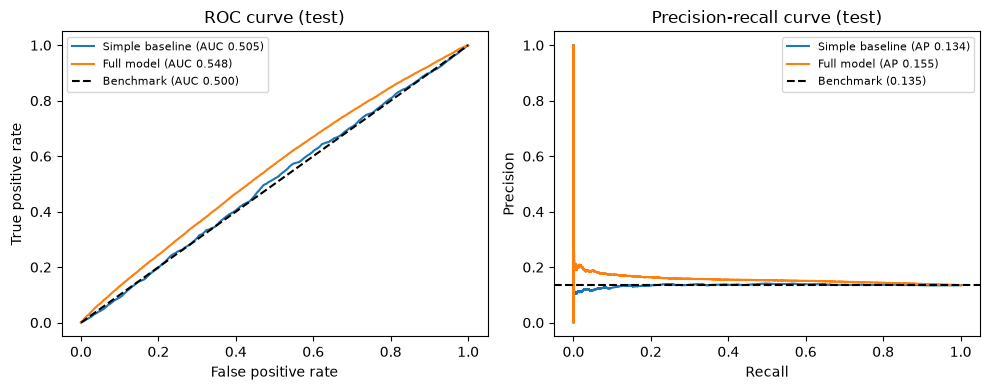

In [13]:
# Figure 1 & 2: ROC and precision-recall curves (test set)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for name, p in [("Simple baseline", p_simple), ("Full model", p_full)]:
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="Benchmark (AUC 0.500)")
ax[1].axhline(y_test.mean(), color="k", ls="--", label=f"Benchmark ({y_test.mean():.3f})")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test)")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test)")
for a in ax: a.legend(loc="best", fontsize=8)
plt.tight_layout(); plt.savefig("fig4_roc_pr.png", dpi=300, bbox_inches="tight"); plt.show()


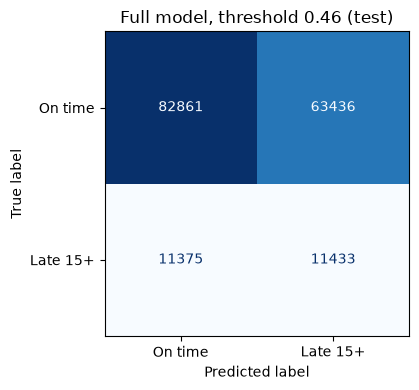

In [14]:
# Figure 3: confusion matrix for the full model (test set)
fig, ax = plt.subplots(figsize=(4.5, 4))
cm = confusion_matrix(y_test, (p_full >= thr_f).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["On time", "Late 15+"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Full model, threshold {thr_f:.2f} (test)")
plt.tight_layout(); plt.savefig("fig5_confusion.png", dpi=300, bbox_inches="tight"); plt.show()

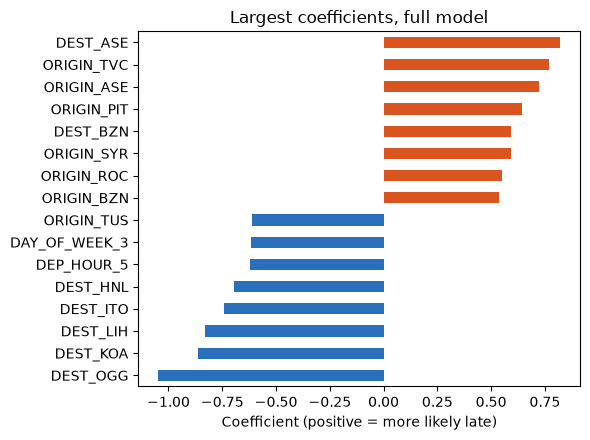

In [15]:
# Figure 4: largest coefficients of the full model (what drives predictions)
names = full_pre.get_feature_names_out()
w = pd.Series(full_model.linear.weight.detach().numpy().ravel(), index=names)
w.index = [n.replace("cat__", "").replace("num__", "") for n in w.index]
top = pd.concat([w.sort_values().head(8), w.sort_values().tail(8)])
fig, ax = plt.subplots(figsize=(6, 4.5))
top.plot(kind="barh", color=["#2a6fbb" if v < 0 else "#d9541e" for v in top], ax=ax)
ax.set(xlabel="Coefficient (positive = more likely late)", title="Largest coefficients, full model")
plt.tight_layout(); plt.savefig("fig6_coef.png", dpi=300, bbox_inches="tight"); plt.show()

## 7. Cases of interest

In [16]:
cases = test.copy()
cases["P(late)"] = p_full.round(3); cases["Actual"] = np.where(y_test == 1, "late", "on time")
cols = ["FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "DEP_HOUR", "DISTANCE", "P(late)", "Actual"]
print("Correct, most confident late flight:");   display(cases[cases.Actual == "late"].nlargest(1, "P(late)")[cols])
print("Wrong, most confident false alarm (predicted late, arrived on time):"); display(cases[cases.Actual == "on time"].nlargest(1, "P(late)")[cols])
print("Wrong, most confident miss (late flight given the lowest probability):"); display(cases[cases.Actual == "late"].nsmallest(1, "P(late)")[cols])

Correct, most confident late flight:


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,DEP_HOUR,DISTANCE,P(late),Actual
94119,2025-01-27,OO,DEN,ASE,17,125.0,0.856,late


Wrong, most confident false alarm (predicted late, arrived on time):


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,DEP_HOUR,DISTANCE,P(late),Actual
94121,2025-01-27,OO,DEN,ASE,20,125.0,0.87,on time


Wrong, most confident miss (late flight given the lowest probability):


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,DEP_HOUR,DISTANCE,P(late),Actual
10870,2025-01-22,UA,SFO,LIH,8,2447.0,0.076,late
